# PredictMaint PY: Manutenção Preditiva com Machine Learning

**Contexto:** paradas não planejadas na linha de produção geram custo e atraso. A partir de 10.000 leituras de sensores (temperatura, rotação, torque e desgaste da ferramenta), este notebook constrói um pipeline que prevê se uma máquina vai falhar (`falha_maquina` = 1) ou operar normalmente (0).

**Objetivo:** comparar KNN e Árvore de Decisão e indicar o modelo de maior acurácia nos dados de teste.

## Configuração

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from imblearn.over_sampling import SMOTE

SEED = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
print("Ambiente pronto")

Ambiente pronto


   ## Fase 1: Análise Exploratória (EDA)

In [2]:
df = pd.read_csv("data/manutencao_preditiva.csv", sep=";")

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   udi                      10000 non-null  int64  
 1   id_produto               10000 non-null  str    
 2   tipo                     10000 non-null  str    
 3   temperatura_ar_k         9500 non-null   float64
 4   temperatura_processo_k   9500 non-null   float64
 5   velocidade_rotacao_rpm   9500 non-null   float64
 6   torque_nm                9500 non-null   float64
 7   desgaste_ferramenta_min  10000 non-null  int64  
 8   falha_maquina            10000 non-null  int64  
 9   falha_twf                10000 non-null  int64  
 10  falha_hdf                10000 non-null  int64  
 11  falha_pwf                10000 non-null  int64  
 12  falha_osf                10000 non-null  int64  
 13  falha_rnf                10000 non-null  int64  
dtypes: float64(4), int64(8), str(2)
me

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
udi,10000.0,5000.500000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
temperatura_ar_k,9500.0,300.002158,2.001689,295.3,298.30,300.1,301.50,304.5
temperatura_processo_k,9500.0,310.000895,1.486432,305.7,308.80,310.1,311.10,313.8
velocidade_rotacao_rpm,9500.0,1539.245263,180.273589,1168.0,1423.00,1504.0,1613.00,2886.0
torque_nm,9500.0,39.974168,9.995453,3.8,33.10,40.1,46.70,76.6
desgaste_ferramenta_min,10000.0,107.951000,63.654147,0.0,53.00,108.0,162.00,253.0
falha_maquina,10000.0,0.033900,0.180981,0.0,0.00,0.0,0.00,1.0
falha_twf,10000.0,0.004600,0.067671,0.0,0.00,0.0,0.00,1.0
falha_hdf,10000.0,0.011500,0.106625,0.0,0.00,0.0,0.00,1.0
falha_pwf,10000.0,0.009500,0.097009,0.0,0.00,0.0,0.00,1.0


In [5]:
print("Valores nulos por coluna:")
print(df.isna().sum()[lambda s: s > 0])
print()
print("Linhas duplicadas:", df.duplicated().sum())
print("Valores repetidos em udi:", df["udi"].duplicated().sum())

Valores nulos por coluna:
temperatura_ar_k          500
temperatura_processo_k    500
velocidade_rotacao_rpm    500
torque_nm                 500
dtype: int64

Linhas duplicadas: 0
Valores repetidos em udi: 0


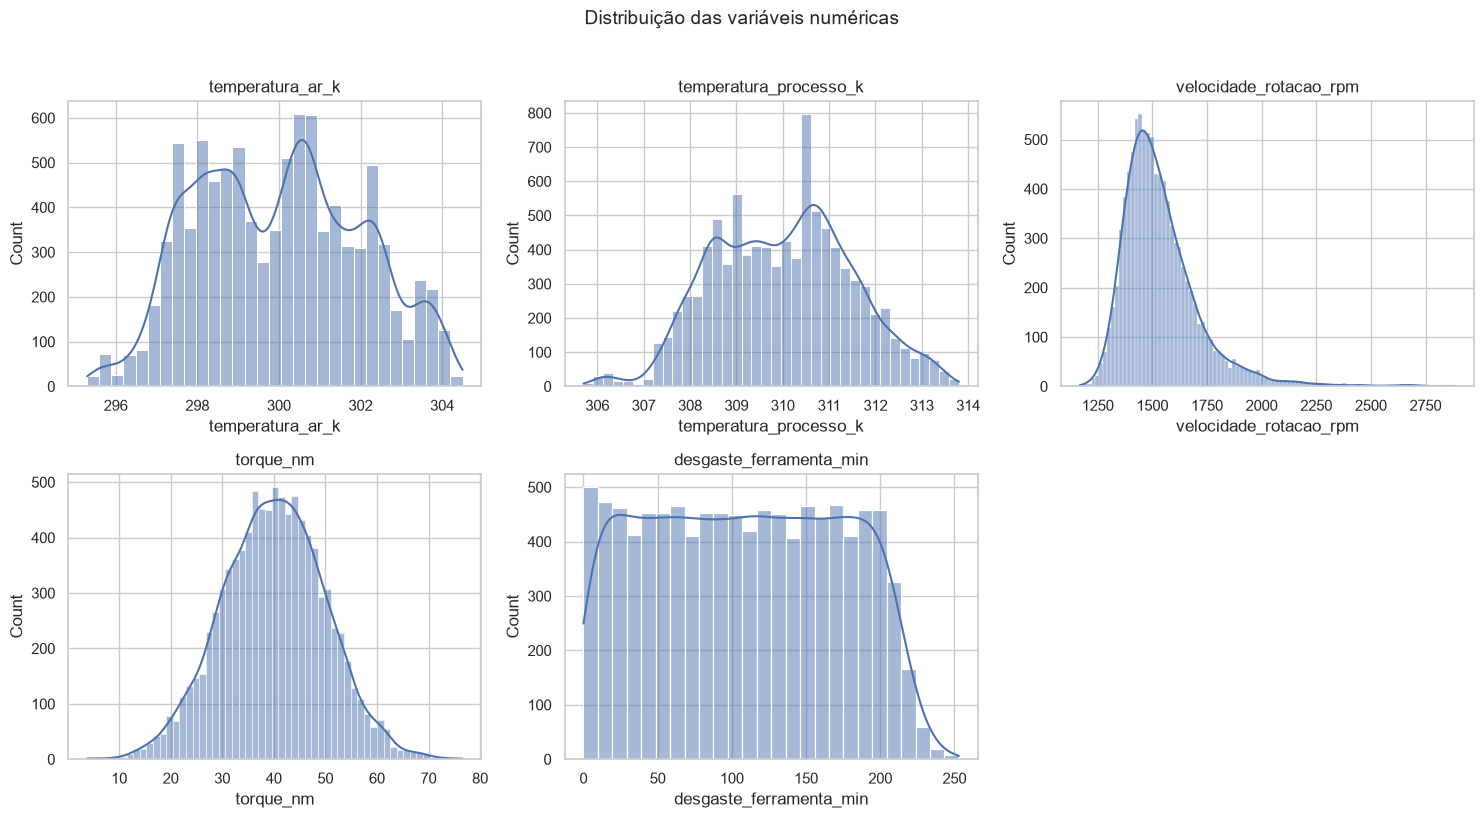

In [6]:
colunas_num = [
    "temperatura_ar_k",
    "temperatura_processo_k",
    "velocidade_rotacao_rpm",
    "torque_nm",
    "desgaste_ferramenta_min",
]

fig, eixos = plt.subplots(2, 3, figsize=(15, 8))
eixos = eixos.flatten()
for eixo, coluna in zip(eixos, colunas_num):
    sns.histplot(df[coluna], kde=True, ax=eixo)
    eixo.set_title(coluna)
eixos[-1].set_visible(False)
fig.suptitle("Distribuição das variáveis numéricas", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

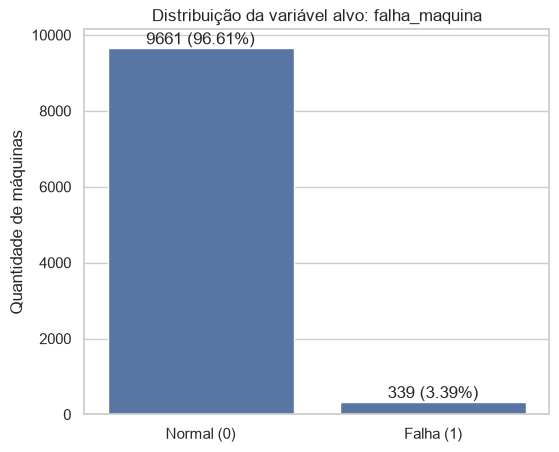

Acurácia ingênua (sempre prever 0): 96.61%


In [7]:
contagem = df["falha_maquina"].value_counts().sort_index()
percentual = df["falha_maquina"].value_counts(normalize=True).sort_index() * 100

fig, eixo = plt.subplots(figsize=(6, 5))
sns.barplot(x=["Normal (0)", "Falha (1)"], y=contagem.values, ax=eixo)
for i, (qtd, pct) in enumerate(zip(contagem.values, percentual.values)):
    eixo.text(i, qtd, f"{qtd} ({pct:.2f}%)", ha="center", va="bottom")
eixo.set_title("Distribuição da variável alvo: falha_maquina")
eixo.set_ylabel("Quantidade de máquinas")
plt.show()

print(f"Acurácia ingênua (sempre prever 0): {percentual.loc[0]:.2f}%")

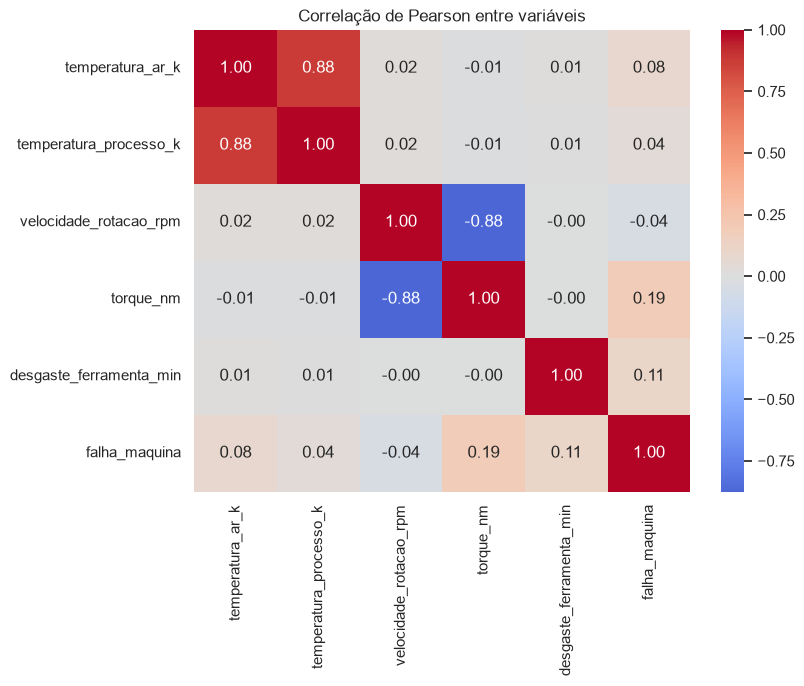

In [8]:
correlacao = df[colunas_num + ["falha_maquina"]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlação de Pearson entre variáveis")
plt.show()

### Análise exploratória

**Estrutura da base.** O dataset tem 10.000 linhas e 14 colunas, sem nenhum registro duplicado. Os tipos são adequados: `tipo` e `id_produto` são texto, os sensores são numéricos e as colunas de falha são binárias (0 ou 1). Quatro colunas de sensores (`temperatura_ar_k`, `temperatura_processo_k`, `velocidade_rotacao_rpm` e `torque_nm`) têm 500 valores nulos cada, 5% da base, sempre nas mesmas linhas. Esse ponto será tratado na Fase 2.

**Distribuições.** As variáveis têm escalas muito diferentes: a rotação gira em torno de 1.539 rpm, o torque em torno de 40 Nm e as temperaturas em torno de 300 K. A rotação é a única com distribuição claramente assimétrica, com cauda à direita e máximo de 2.886 rpm. Temperaturas, torque e desgaste têm formato próximo ao simétrico.

**Variável alvo.** Há forte desbalanceamento: apenas 339 máquinas (3,39%) falharam. Um modelo que sempre prevê "sem falha" acertaria 96,61% dos casos sem detectar nenhuma quebra. Essa acurácia ingênua será a referência de comparação na Fase 7.

**Correlações.** As duas temperaturas são fortemente correlacionadas entre si (0,88), o que indica informação em parte redundante. Em relação à falha, o torque tem a correlação mais forte (0,19), seguido do desgaste da ferramenta (0,11). Todas são fracas, o que sugere relações não lineares e justifica testar modelos como KNN e Árvore de Decisão.

**Implicações para a modelagem.** O desbalanceamento exige divisão estratificada e SMOTE aplicado só no treino. As escalas diferentes exigem StandardScaler no KNN. A assimetria da rotação orienta o uso da mediana na imputação. A relação entre torque, rotação e falha motiva criar a variável `potencia`.

## Fase 2: Limpeza e Tratamento (Data Prep)

In [9]:
print("Linhas antes:", df.shape[0])
print("Linhas duplicadas:", df.duplicated().sum())
print("udi repetidos:", df["udi"].duplicated().sum())
print("id_produto repetidos:", df["id_produto"].duplicated().sum())

df = df.drop_duplicates()
print("Linhas depois:", df.shape[0])

Linhas antes: 10000
Linhas duplicadas: 0
udi repetidos: 0
id_produto repetidos: 0
Linhas depois: 10000


In [10]:
nulos = df.isna().sum()
tabela_nulos = pd.DataFrame({
    "nulos": nulos,
    "percentual": (nulos / len(df) * 100).round(2),
})
tabela_nulos[tabela_nulos["nulos"] > 0]

,nulos,percentual
temperatura_ar_k,500,5.0
temperatura_processo_k,500,5.0
velocidade_rotacao_rpm,500,5.0
torque_nm,500,5.0


In [11]:
colunas_nulas = ["temperatura_ar_k", "temperatura_processo_k", "velocidade_rotacao_rpm", "torque_nm"]

comparacao = pd.DataFrame({
    "media": df[colunas_nulas].mean(),
    "mediana": df[colunas_nulas].median(),
    "assimetria": df[colunas_nulas].skew(),
}).round(2)
comparacao

,media,mediana,assimetria
temperatura_ar_k,300.00,300.1,0.11
temperatura_processo_k,310.00,310.1,0.02
velocidade_rotacao_rpm,1539.25,1504.0,1.99
torque_nm,39.97,40.1,-0.01


### Decisão sobre os valores nulos

Os 500 nulos (5% da base) aparecem sempre nas mesmas linhas e nas quatro colunas de sensores. Descartar essas linhas faria perder 5% dos dados, inclusive 17 registros de falha, que é a classe mais rara. Por isso a escolha foi imputar.

A escolha entre média e mediana foi feita pela assimetria de cada coluna:

- **`velocidade_rotacao_rpm`: mediana.** A assimetria é 1,99, com cauda longa à direita, e a média (1.539 rpm) fica acima da mediana (1.504 rpm), puxada por valores altos. A mediana representa melhor a rotação típica e não é distorcida pelos extremos.
- **`temperatura_ar_k`, `temperatura_processo_k` e `torque_nm`: média.** As assimetrias ficam entre -0,01 e 0,11 e a média é praticamente igual à mediana. A distribuição é simétrica, então a média é um valor representativo.

`desgaste_ferramenta_min` não tem nulos e não precisa de tratamento.

In [12]:
df["velocidade_rotacao_rpm"] = df["velocidade_rotacao_rpm"].fillna(df["velocidade_rotacao_rpm"].median())

for coluna in ["temperatura_ar_k", "temperatura_processo_k", "torque_nm"]:
    df[coluna] = df[coluna].fillna(df[coluna].mean())

print("Nulos restantes:", df.isna().sum().sum())

Nulos restantes: 0


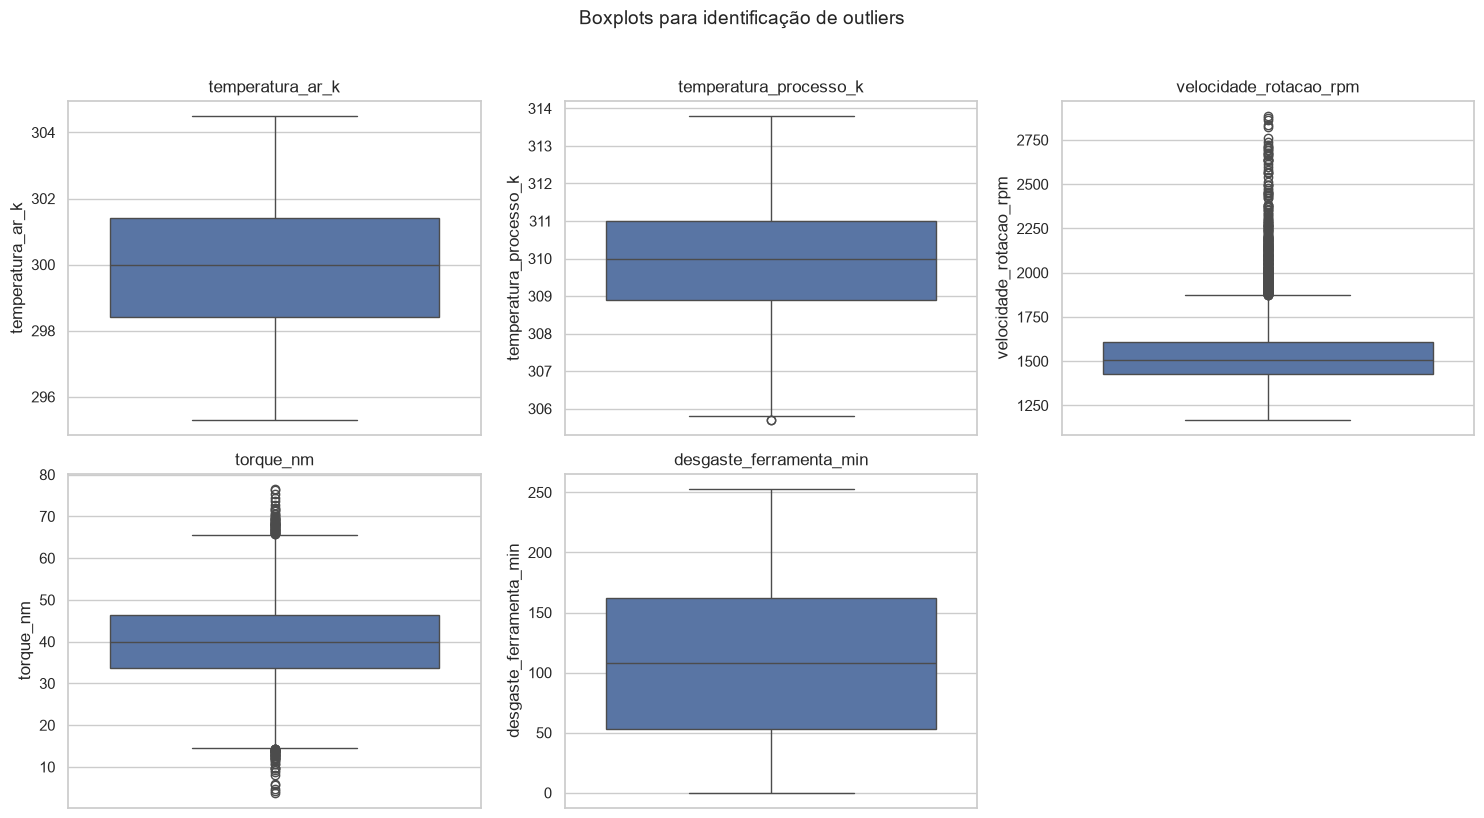

In [13]:
colunas_num = [
    "temperatura_ar_k",
    "temperatura_processo_k",
    "velocidade_rotacao_rpm",
    "torque_nm",
    "desgaste_ferramenta_min",
]

fig, eixos = plt.subplots(2, 3, figsize=(15, 8))
eixos = eixos.flatten()
for eixo, coluna in zip(eixos, colunas_num):
    sns.boxplot(y=df[coluna], ax=eixo)
    eixo.set_title(coluna)
eixos[-1].set_visible(False)
fig.suptitle("Boxplots para identificação de outliers", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [14]:
q1 = df[colunas_num].quantile(0.25)
q3 = df[colunas_num].quantile(0.75)
iqr = q3 - q1
limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr

outliers = ((df[colunas_num] < limite_inf) | (df[colunas_num] > limite_sup)).sum()
pd.DataFrame({"outliers": outliers, "percentual": (outliers / len(df) * 100).round(2)})

,outliers,percentual
temperatura_ar_k,0,0.00
temperatura_processo_k,2,0.02
velocidade_rotacao_rpm,465,4.65
torque_nm,102,1.02
desgaste_ferramenta_min,0,0.00


### Decisão sobre os outliers

Pelo critério do intervalo interquartil (1,5 × IQR), os outliers se concentram em `velocidade_rotacao_rpm` (465 registros, 4,65%) e `torque_nm` (102 registros, 1,02%). Temperaturas e desgaste da ferramenta praticamente não têm.

Esses valores foram **mantidos**. Em manutenção preditiva, rotações e torques extremos costumam indicar sobrecarga do equipamento, que é justamente o sinal que antecede uma falha, e removê-los eliminaria exemplos de que o modelo precisa para aprender. Os valores também são fisicamente plausíveis, e as anotações da Engenharia não os apontam como erro de leitura. Além disso, a Árvore de Decisão não é sensível a outliers, e o KNN receberá as variáveis escalonadas na Fase 5.

## Fase 3: Feature Engineering

In [15]:
df["potencia"] = df["velocidade_rotacao_rpm"] * df["torque_nm"]

print("Nulos em potencia:", df["potencia"].isna().sum())
print("Infinitos em potencia:", np.isinf(df["potencia"]).sum())
df["potencia"].describe().round(2)

Nulos em potencia: 0
Infinitos em potencia: 0


count    10000.00
mean     59961.21
std       9951.11
min      10966.80
25%      53497.05
50%      60121.15
75%      66412.98
max      99980.40
Name: potencia, dtype: float64

                  mean   median
falha_maquina                  
0              59646.0  60121.0
1              68956.0  71505.0


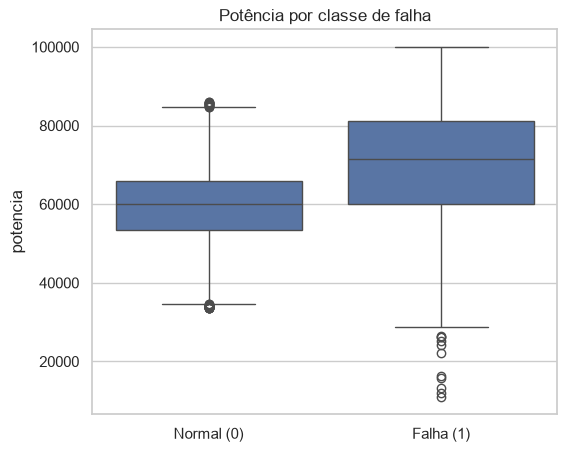

In [16]:
print(df.groupby("falha_maquina")["potencia"].agg(["mean", "median"]).round(0))

plt.figure(figsize=(6, 5))
sns.boxplot(x="falha_maquina", y="potencia", data=df)
plt.xticks([0, 1], ["Normal (0)", "Falha (1)"])
plt.xlabel("")
plt.title("Potência por classe de falha")
plt.show()

### Nova variável: `potencia`

Foi criada a coluna `potencia = velocidade_rotacao_rpm * torque_nm`, combinação sugerida no enunciado do projeto. Ela é calculada depois da imputação dos nulos, por isso não tem valores ausentes nem infinitos.

**Por que faz sentido.** Em máquinas rotativas, a potência é proporcional ao produto do torque pela velocidade de rotação. A variável resume em um único número o esforço que a máquina está fazendo, algo que `torque_nm` e `velocidade_rotacao_rpm` sozinhas não mostram. Na análise exploratória elas têm correlação de -0,88 entre si, então uma sobe quando a outra desce, e o produto captura justamente essa relação.

**O que os dados mostram.** A potência média das máquinas que falharam é de 68.956, contra 59.646 das que operaram normalmente (cerca de 16% maior), e a mediana vai de 60.121 para 71.505. No boxplot, a caixa da classe "Falha" fica bem acima da caixa "Normal". Também aparecem falhas com potência muito baixa, o que indica que a variável ajuda a separar as duas classes nos dois extremos.

As colunas originais foram mantidas, e `potencia` entra como uma variável a mais no modelo.

## Fase 4: Divisão e Balanceamento

In [17]:
colunas_fora = ["udi", "id_produto", "falha_maquina",
                "falha_twf", "falha_hdf", "falha_pwf", "falha_osf", "falha_rnf"]

X = df.drop(columns=colunas_fora)
X = pd.get_dummies(X, columns=["tipo"], drop_first=True, dtype=int)
y = df["falha_maquina"]

print("Formato de X:", X.shape)
print("Colunas de X:", list(X.columns))
print()
print(y.value_counts())

Formato de X: (10000, 8)
Colunas de X: ['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min', 'potencia', 'tipo_L', 'tipo_M']

falha_maquina
0    9661
1     339
Name: count, dtype: int64


In [18]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print("Treino:", X_treino.shape, "| Teste:", X_teste.shape)
print()
print("Falhas no treino:", y_treino.sum(), f"({y_treino.mean() * 100:.2f}%)")
print("Falhas no teste: ", y_teste.sum(), f"({y_teste.mean() * 100:.2f}%)")

Treino: (8000, 8) | Teste: (2000, 8)

Falhas no treino: 271 (3.39%)
Falhas no teste:  68 (3.40%)


In [19]:
print("Antes do SMOTE:", y_treino.value_counts().to_dict())

smote = SMOTE(random_state=SEED)
X_treino_bal, y_treino_bal = smote.fit_resample(X_treino, y_treino)

print("Depois do SMOTE:", y_treino_bal.value_counts().to_dict())
print("Formato do treino balanceado:", X_treino_bal.shape)
print("Teste (inalterado):", y_teste.value_counts().to_dict())

Antes do SMOTE: {0: 7729, 1: 271}
Depois do SMOTE: {0: 7729, 1: 7729}
Formato do treino balanceado: (15458, 8)
Teste (inalterado): {0: 1932, 1: 68}


### Decisões da divisão e do balanceamento

**Variáveis usadas.** Ficaram fora do modelo os identificadores (`udi`, `id_produto`) e as cinco colunas de tipo de falha (`falha_twf`, `falha_hdf`, `falha_pwf`, `falha_osf`, `falha_rnf`). Elas descrevem a causa da falha, que só se conhece depois que ela acontece, e usá-las seria vazamento de dados: o modelo "acertaria" por consulta ao gabarito, e não por aprendizado. A coluna `tipo` (L, M, H) foi transformada em numérica com `get_dummies(drop_first=True)`, gerando `tipo_L` e `tipo_M`.

**Divisão.** Foram separados 80% dos dados para treino (8.000 linhas) e 20% para teste (2.000 linhas), com `random_state=42` para o resultado ser reproduzível. O parâmetro `stratify=y` mantém a proporção de falhas igual nos dois grupos (3,39% no treino e 3,40% no teste). Sem ele, como a classe de falha é muito rara, o teste poderia ficar com poucas falhas ou nenhuma, e a avaliação perderia o sentido.

**Balanceamento.** Apenas 3,39% das máquinas falham, então um modelo que sempre prevê "normal" já acerta 96,61% sem aprender nada. Para que os modelos aprendam também o padrão da falha, aplicou-se o SMOTE, que cria exemplos sintéticos da classe minoritária a partir de vizinhos reais. O treino passou de 7.729 normais e 271 falhas para 7.729 de cada.

**Cuidado com o vazamento.** O SMOTE foi aplicado **somente ao conjunto de treino**, depois da divisão. O conjunto de teste permanece com a distribuição real (1.932 normais e 68 falhas), porque ele precisa simular os dados que o modelo vai encontrar na prática. Balancear antes de dividir colocaria exemplos sintéticos, derivados de dados do teste, dentro do treino, o que inflaria a acurácia de forma artificial.

## Fase 5: Escalonamento (StandardScaler)

In [20]:
scaler = StandardScaler()

X_treino_esc = pd.DataFrame(
    scaler.fit_transform(X_treino_bal), columns=X_treino_bal.columns
)
X_teste_esc = pd.DataFrame(
    scaler.transform(X_teste), columns=X_teste.columns
)

resumo = pd.DataFrame({
    "media_treino": X_treino_esc.mean(),
    "desvio_treino": X_treino_esc.std(ddof=0),
    "media_teste": X_teste_esc.mean(),
    "desvio_teste": X_teste_esc.std(ddof=0),
}).round(2)
resumo

,media_treino,desvio_treino,media_teste,desvio_teste
temperatura_ar_k,-0.0,1.0,-0.22,1.05
temperatura_processo_k,0.0,1.0,-0.12,1.14
velocidade_rotacao_rpm,0.0,1.0,0.05,0.58
torque_nm,0.0,1.0,-0.34,0.68
desgaste_ferramenta_min,0.0,1.0,-0.22,0.96
potencia,0.0,1.0,-0.31,0.66
tipo_L,0.0,1.0,0.03,1.00
tipo_M,0.0,1.0,0.32,1.19


### Decisões do escalonamento

**Por que escalonar.** As variáveis estão em escalas muito diferentes: `potencia` passa de 60.000, a rotação fica em torno de 1.500 rpm, o torque em torno de 40 Nm e as colunas `tipo_L` e `tipo_M` valem só 0 ou 1. O KNN classifica pela distância entre os pontos, e sem ajuste as variáveis de maior escala dominariam o cálculo e as demais quase não teriam influência. O `StandardScaler` transforma cada variável para média 0 e desvio padrão 1, e todas passam a contribuir de forma comparável.

**Só para o KNN.** A Árvore de Decisão decide por cortes em cada variável isoladamente, então a escala não altera os resultados. Por isso a árvore usa `X_treino_bal` e `X_teste` originais, e apenas o KNN usa `X_treino_esc` e `X_teste_esc`.

**Sem vazamento de dados.** O `fit` do escalonador foi feito somente no treino balanceado, e o teste recebeu apenas o `transform`, com a média e o desvio aprendidos no treino. Se o teste participasse do `fit`, informações dele vazariam para o pré-processamento e a avaliação ficaria otimista.

**Como ler a tabela.** No treino, a média é 0 e o desvio é 1 em todas as colunas, como esperado. No teste os valores ficam próximos, mas não iguais: ele foi transformado com as estatísticas do treino, e o treino balanceado tem mais falhas, que têm torque e potência mais altos. Essa diferença é o comportamento correto, e não um erro.

## Fase 6: Ajuste de Parâmetros e Overfitting

In [21]:
valores_k = [1, 3, 5, 7, 9, 11, 15, 21, 31]
resultados_knn = []

for k in valores_k:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_treino_esc, y_treino_bal)
    acc_treino = accuracy_score(y_treino_bal, knn.predict(X_treino_esc))
    acc_teste = accuracy_score(y_teste, knn.predict(X_teste_esc))
    resultados_knn.append({
        "K": k,
        "acuracia_treino": round(acc_treino * 100, 2),
        "acuracia_teste": round(acc_teste * 100, 2),
        "diferenca": round((acc_treino - acc_teste) * 100, 2),
    })

tabela_knn = pd.DataFrame(resultados_knn)
tabela_knn

,K,acuracia_treino,acuracia_teste,diferenca
0,1,99.39,91.85,7.54
1,3,96.93,90.60,6.33
2,5,95.90,89.75,6.15
3,7,95.23,89.10,6.13
4,9,94.67,88.70,5.97
5,11,94.27,88.50,5.77
6,15,93.68,88.35,5.33
7,21,93.06,88.00,5.06
8,31,92.35,87.10,5.25


In [22]:
profundidades = [1, 2, 3, 4, 5, 7, 10, 15, None]
resultados_arvore = []

for prof in profundidades:
    arvore = DecisionTreeClassifier(max_depth=prof, random_state=SEED)
    arvore.fit(X_treino_bal, y_treino_bal)
    acc_treino = accuracy_score(y_treino_bal, arvore.predict(X_treino_bal))
    acc_teste = accuracy_score(y_teste, arvore.predict(X_teste))
    resultados_arvore.append({
        "max_depth": "sem limite" if prof is None else prof,
        "acuracia_treino": round(acc_treino * 100, 2),
        "acuracia_teste": round(acc_teste * 100, 2),
        "diferenca": round((acc_treino - acc_teste) * 100, 2),
    })

tabela_arvore = pd.DataFrame(resultados_arvore)
tabela_arvore

,max_depth,acuracia_treino,acuracia_teste,diferenca
0,1,75.23,85.90,-10.67
1,2,80.69,89.40,-8.71
2,3,85.69,84.70,0.99
3,4,88.31,89.85,-1.54
4,5,90.26,90.20,0.06
5,7,91.56,93.40,-1.84
6,10,95.29,93.00,2.29
7,15,98.90,93.80,5.10
8,sem limite,99.56,94.20,5.36


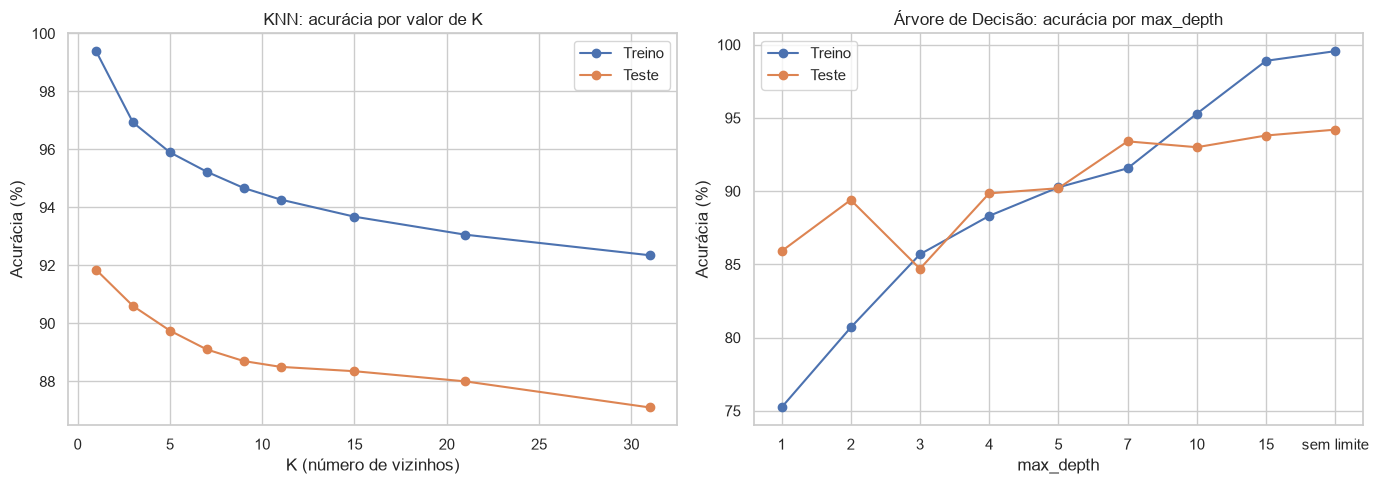

In [23]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 5))

eixos[0].plot(tabela_knn["K"], tabela_knn["acuracia_treino"], marker="o", label="Treino")
eixos[0].plot(tabela_knn["K"], tabela_knn["acuracia_teste"], marker="o", label="Teste")
eixos[0].set_title("KNN: acurácia por valor de K")
eixos[0].set_xlabel("K (número de vizinhos)")
eixos[0].set_ylabel("Acurácia (%)")
eixos[0].legend()

posicoes = range(len(tabela_arvore))
eixos[1].plot(posicoes, tabela_arvore["acuracia_treino"], marker="o", label="Treino")
eixos[1].plot(posicoes, tabela_arvore["acuracia_teste"], marker="o", label="Teste")
eixos[1].set_xticks(list(posicoes))
eixos[1].set_xticklabels(tabela_arvore["max_depth"].astype(str))
eixos[1].set_title("Árvore de Decisão: acurácia por max_depth")
eixos[1].set_xlabel("max_depth")
eixos[1].set_ylabel("Acurácia (%)")
eixos[1].legend()

plt.tight_layout()
plt.show()

### Análise do ajuste de parâmetros e do overfitting

**O que foi testado.** No KNN, variou-se o número de vizinhos `K` (1, 3, 5, 7, 9, 11, 15, 21 e 31), usando os dados escalonados. Na Árvore de Decisão, variou-se a profundidade `max_depth` (1, 2, 3, 4, 5, 7, 10, 15 e sem limite), usando os dados originais. Para cada valor, comparou-se a acurácia no treino com a acurácia no teste.

**KNN.** A acurácia no treino é sempre maior que a do teste, o que indica overfitting em todos os valores de `K`. A diferença é maior com `K=1` (99,39% no treino contra 91,85% no teste, 7,54 pontos), porque o modelo decora cada exemplo, e diminui conforme `K` cresce (5,25 pontos com `K=31`). Porém, aumentar `K` não melhora o resultado: a acurácia no teste cai de 91,85% para 87,10%. Ou seja, suavizar o modelo reduziu o overfitting, mas piorou o desempenho real, e o melhor valor de `K` no teste foi **K=1**.

**Árvore de Decisão.** Com profundidade pequena (1 a 3), a árvore é simples demais e não aprende bem o padrão da falha. Conforme a profundidade aumenta, as duas acurácias sobem juntas até `max_depth=7` (91,56% no treino e 93,40% no teste, sem sinal de overfitting). A partir daí o treino continua subindo, chegando a 99,56% sem limite de profundidade, enquanto o teste sobe pouco (94,20%). A distância entre treino e teste passa de zero para cerca de 5 pontos, o que é overfitting moderado. O melhor valor no teste foi **sem limite de profundidade (94,20%)**, e `max_depth=7` é a alternativa mais equilibrada, com apenas 0,8 ponto a menos.

**Parâmetros escolhidos.** Seguindo o critério do projeto (maior acurácia no teste), a Fase 7 usa `K=1` no KNN e `max_depth=None` na Árvore de Decisão. Vale observar que escolher parâmetros olhando o próprio conjunto de teste tende a deixar o resultado um pouco otimista, e que a acurácia do treino é medida em dados balanceados (50% de falhas) enquanto a do teste usa a proporção real (3,4% de falhas), então a comparação entre as duas serve para ver a tendência, não a diferença exata.

## Fase 7: Avaliação da Acurácia e Veredito Final

In [24]:
knn_final = KNeighborsClassifier(n_neighbors=1)
knn_final.fit(X_treino_esc, y_treino_bal)
previsoes_knn = knn_final.predict(X_teste_esc)

arvore_final = DecisionTreeClassifier(max_depth=None, random_state=SEED)
arvore_final.fit(X_treino_bal, y_treino_bal)
previsoes_arvore = arvore_final.predict(X_teste)

acc_knn = accuracy_score(y_teste, previsoes_knn)
acc_arvore = accuracy_score(y_teste, previsoes_arvore)

print(f"Acurácia KNN (K=1) no teste:                 {acc_knn * 100:.2f}%")
print(f"Acurácia Árvore (sem limite) no teste:       {acc_arvore * 100:.2f}%")

Acurácia KNN (K=1) no teste:                 91.85%
Acurácia Árvore (sem limite) no teste:       94.20%


                             modelo  acuracia_teste
0                         KNN (K=1)           91.85
1    Árvore de Decisão (sem limite)           94.20
2  Referência: sempre prever normal           96.60


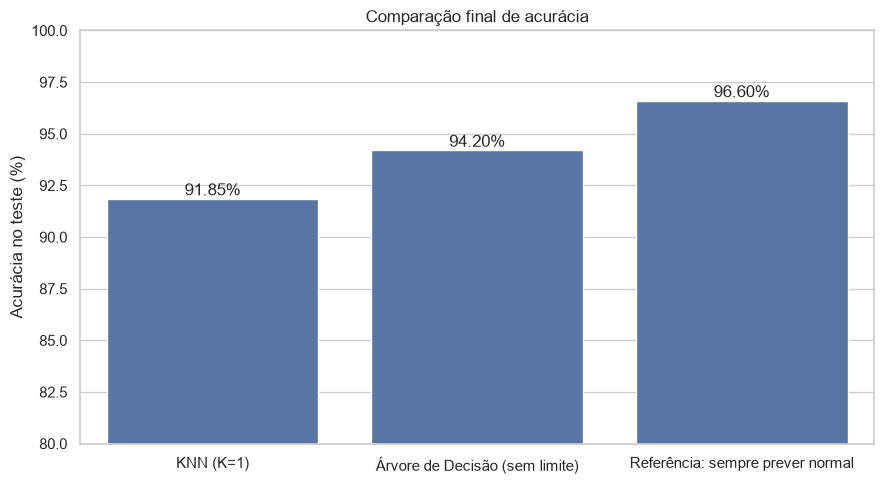

In [25]:
acc_referencia = (y_teste == 0).mean()

comparacao_final = pd.DataFrame({
    "modelo": ["KNN (K=1)", "Árvore de Decisão (sem limite)", "Referência: sempre prever normal"],
    "acuracia_teste": [round(acc_knn * 100, 2), round(acc_arvore * 100, 2), round(acc_referencia * 100, 2)],
})
print(comparacao_final)

plt.figure(figsize=(9, 5))
ax = sns.barplot(x="modelo", y="acuracia_teste", data=comparacao_final)
for barra in ax.patches:
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(),
            f"{barra.get_height():.2f}%", ha="center", va="bottom")
ax.set_ylim(80, 100)
ax.set_xlabel("")
ax.set_ylabel("Acurácia no teste (%)")
ax.set_title("Comparação final de acurácia")
plt.tight_layout()
plt.show()

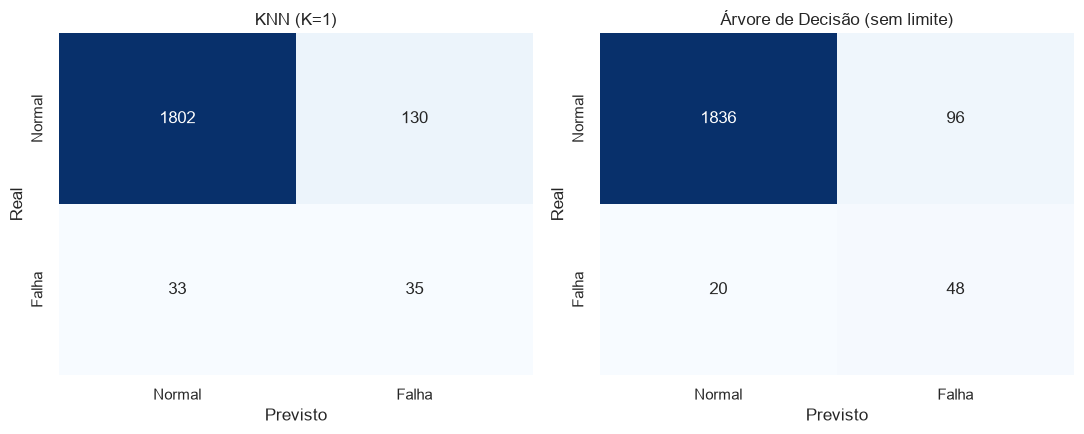

=== KNN (K=1) ===
              precision    recall  f1-score   support

      Normal       0.98      0.93      0.96      1932
       Falha       0.21      0.51      0.30        68

    accuracy                           0.92      2000
   macro avg       0.60      0.72      0.63      2000
weighted avg       0.96      0.92      0.93      2000

=== Árvore de Decisão (sem limite) ===
              precision    recall  f1-score   support

      Normal       0.99      0.95      0.97      1932
       Falha       0.33      0.71      0.45        68

    accuracy                           0.94      2000
   macro avg       0.66      0.83      0.71      2000
weighted avg       0.97      0.94      0.95      2000



In [26]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5))

for eixo, titulo, previsoes in [
    (eixos[0], "KNN (K=1)", previsoes_knn),
    (eixos[1], "Árvore de Decisão (sem limite)", previsoes_arvore),
]:
    matriz = confusion_matrix(y_teste, previsoes)
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, ax=eixo,
                xticklabels=["Normal", "Falha"], yticklabels=["Normal", "Falha"])
    eixo.set_title(titulo)
    eixo.set_xlabel("Previsto")
    eixo.set_ylabel("Real")

plt.tight_layout()
plt.show()

print("=== KNN (K=1) ===")
print(classification_report(y_teste, previsoes_knn, target_names=["Normal", "Falha"]))
print("=== Árvore de Decisão (sem limite) ===")
print(classification_report(y_teste, previsoes_arvore, target_names=["Normal", "Falha"]))

### Veredito final

**Critério.** Conforme o enunciado, o melhor modelo é o de maior acurácia nos dados de teste, que o modelo nunca viu durante o treino.

| Modelo | Parâmetro | Acurácia no teste | Falhas detectadas (de 68) |
|---|---|---|---|
| KNN | K=1 | 91,85% | 35 (51%) |
| Árvore de Decisão | max_depth=None | **94,20%** | 48 (71%) |

**Vencedor: Árvore de Decisão**, com 94,20% de acurácia contra 91,85% do KNN, uma vantagem de 2,35 pontos percentuais (47 máquinas a mais classificadas corretamente entre as 2.000 do teste). Ela também foi melhor onde mais importa: detectou 48 das 68 falhas reais (recall de 71%), contra 35 do KNN (51%), e gerou menos alarmes falsos (96 contra 130).

**Por que a árvore se saiu melhor.** O KNN com `K=1` é sensível a ruído, pois decide pelo vizinho mais próximo, e o balanceamento com SMOTE cria pontos sintéticos que podem confundir essa vizinhança. A árvore separa as classes por cortes em variáveis como `torque_nm`, `potencia` e `desgaste_ferramenta_min`, o que combina bem com o padrão de sobrecarga que antecede as falhas. A conclusão se mantém mesmo com uma árvore mais simples: com `max_depth=7`, a acurácia no teste foi 93,40%, ainda acima do melhor KNN.

**Limites do resultado.**
- A acurácia dos dois modelos ficou abaixo da referência de 96,60%, que é a de quem sempre prevê "normal". Isso acontece porque só 3,4% das máquinas falham. A referência não detecta nenhuma falha, e os modelos detectam entre 51% e 71%, o que é o que tem valor para a manutenção. Os modelos trocam alguns alarmes falsos por falhas encontradas.
- Os parâmetros foram escolhidos olhando o próprio conjunto de teste, então os valores finais tendem a ser um pouco otimistas.
- A avaliação usa uma única divisão treino/teste. Validação cruzada daria uma estimativa mais estável.

## Conclusão e Melhorias

### Conclusão

Este notebook construiu um pipeline completo de manutenção preditiva sobre 10.000 leituras de sensores: análise exploratória, limpeza (sem duplicados, 2.000 nulos imputados com média ou mediana conforme a assimetria, outliers mantidos por representarem sobrecarga real), criação da variável `potencia`, divisão estratificada 80/20, balanceamento com SMOTE apenas no treino, escalonamento apenas para o KNN e ajuste de `K` e `max_depth` com análise de overfitting.

O modelo vencedor foi a **Árvore de Decisão**, com 94,20% de acurácia no teste contra 91,85% do KNN, e também com melhor detecção de falhas (71% contra 51%). Na prática, a árvore pode apoiar a equipe de manutenção apontando as máquinas com maior risco de falha, para priorizar inspeções.

### Melhorias futuras

- **Métricas além da acurácia.** Como as falhas são raras, usar recall, precisão e F1-score da classe de falha como critério principal de escolha do modelo, já que a acurácia sozinha favorece quem nunca prevê falha.
- **Validação cruzada estratificada e busca de hiperparâmetros** (por exemplo `GridSearchCV`), para escolher parâmetros sem olhar o conjunto de teste e obter uma estimativa mais estável.
- **Outros modelos**, como Random Forest e Gradient Boosting, que costumam superar uma árvore isolada em dados tabulares, e o ajuste do limiar de decisão para controlar o equilíbrio entre falhas detectadas e alarmes falsos.
- **Mais variáveis derivadas**, como a relação entre `desgaste_ferramenta_min` e `torque_nm`, e tratamento dos tipos de falha como problema à parte, caso a Engenharia queira saber a causa e não só se haverá falha.
- **Mais dados de falha**, pois com apenas 339 casos o modelo tem pouco material para aprender a classe rara.